# Portfolio Allocation Project — Part 3: Rolling-Window Backtest

**Goal:** Part 2 tested the minimum-variance portfolio on single years (2020, 2022, 2025). Here we replace that single split with a **rolling backtest** that mimics how the strategy would actually be run. At the end of every month we:

1. take the last **3 years** of daily returns,
2. estimate $\hat\Sigma$ and compute the minimum-variance weights,
3. hold those weights during the **next** month.

Stitching all the months together gives one continuous **out-of-sample** record from February 2019 to October 2026, which covers the COVID crash, the 2022 inflation shock and calmer years.

**Structure:**

| Section | Content |
|---|---|
| 1–2 | Data and the functions from Part 2 |
| 3–4 | Rebalancing dates and the estimation window (how we avoid look-ahead) |
| 5–6 | The backtest loop, the 1/N benchmark and the risk-free rate |
| 7 | Performance metrics (including Sharpe ratios) and growth of $1 |
| 8 | How the weights move over time |
| 9 | Turnover and trading costs |
| 10 | No-trade band: rebalancing only when the weights change enough |
| 11 | Leveraged minimum variance (same risk as 1/N) |
| 12 | Conclusions |

**Input:** `returns.csv` from Part 1 (daily log returns, one column per asset). Section 6 also uses the 3-month T-bill rate, downloaded once and saved to `risk_free.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252
EST_DAYS = 3 * TRADING_DAYS   # 3-year estimation window = 756 trading days

## 1. Load the returns

In [2]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)
tickers = list(returns.columns)
K = len(tickers)
print(f"{returns.shape[0]} days x {K} assets, from {returns.index[0].date()} to {returns.index[-1].date()}")

2721 days x 10 assets, from 2016-01-05 to 2026-10-29


## 2. Tools from Part 2

The same two functions written in Part 2:

- `min_variance_weights(Sigma)` solves $\Sigma\mathbf x = \boldsymbol\iota$ and normalizes $\mathbf x$ so the weights add up to 1. The backtest calls it once per month.
- `performance(port_returns)` computes the annualized return, volatility, return/volatility ratio and maximum drawdown of a series of daily log returns.

In [3]:
def min_variance_weights(Sigma):
    """Minimum-variance weights (shorting allowed) for a covariance matrix Sigma."""
    iota = np.ones(Sigma.shape[0])
    x = np.linalg.solve(Sigma, iota)
    return x / x.sum()


def performance(port_returns):
    """Annualized metrics for a Series of daily portfolio log returns."""
    ann_return = port_returns.mean() * TRADING_DAYS
    ann_volatility = port_returns.std() * np.sqrt(TRADING_DAYS)
    value = np.exp(port_returns.cumsum())
    drawdown = value / value.cummax() - 1
    return pd.Series({
        "ann_return": ann_return,
        "ann_volatility": ann_volatility,
        "return_over_vol": ann_return / ann_volatility,
        "max_drawdown": drawdown.min(),
    })

## 3. Rebalancing dates

We rebalance at the close of the **last trading day of each month** (for example 29 March 2019, because the 30th and 31st fell on a weekend). Two conditions apply:

- The date needs a **full 3-year window** behind it: at least `EST_DAYS` trading days of history, counting the date itself. If a date sits at position $p$ (counting from 0), it has $p + 1$ days up to and including it, so we need $p \ge$ `EST_DAYS` $- 1$.
- The **last** month-end in the data (29 October 2026) is also the last day of data, so there is nothing left to hold after it. We drop it.

The returns start on 5 January 2016, so the first full window ends on **31 January 2019**.

In [4]:
# Last trading day of each month
month_ends = returns.index.to_series().groupby(returns.index.to_period("M")).max()

# Keep the month-ends with a full 3-year window behind them
eligible = [t for t in month_ends if returns.index.get_loc(t) >= EST_DAYS - 1]

# Drop the last one: it is the last day of data, so there is nothing to hold after it
rebalance_dates = pd.DatetimeIndex(eligible[:-1])

print(f"{len(rebalance_dates)} rebalances, from {rebalance_dates[0].date()} to {rebalance_dates[-1].date()}")

93 rebalances, from 2019-01-31 to 2026-09-30


## 4. The estimation window (no look-ahead)

This is the step where backtests most often go wrong. At a rebalance date $t$ we can only use information available **at the close of $t$**:

- **Estimation window (in-sample):** the last `EST_DAYS` rows of `returns` **ending at $t$** (included).
- **Holding period (out-of-sample):** the days **strictly after $t$**, up to the next rebalance date (included).

```
        estimation window (756 days)           holding period
 |---------------------------------------| t |-------------| t_next
```

If the window included even one day after $t$, the weights would "know the future" and the results would be too good to be true. Each of the 93 windows is therefore a different in-sample period: the first runs from February 2016 to January 2019, and the last from roughly October 2023 to 30 September 2026.

In [5]:
def estimation_window(t):
    """The EST_DAYS rows of returns ending at date t (included)."""
    p = returns.index.get_loc(t)
    window = returns.iloc[p - EST_DAYS + 1 : p + 1]   # .iloc excludes the end, so p + 1 keeps row p
    return window

## 5. The backtest loop

For each rebalance date $t_i$:

1. Estimate $\hat\Sigma$ on `estimation_window(t_i)` and compute the minimum-variance weights.
2. Store the weights, to study them in section 8.
3. Find the holding period: the days after $t_i$ up to $t_{i+1}$. For the **last** rebalance, hold until the last day of data.
4. Compute the portfolio's daily returns in the holding period (`hold @ a`) and store them.

At the end, `pd.concat` joins the 93 monthly pieces into one continuous series of daily returns.

*Simplification (same as Part 2):* within each month the weights stay fixed, which implicitly assumes daily rebalancing back to them.

In [6]:
weights_history = {}   # rebalance date -> weights
monthly_pieces = []    # one Series of daily portfolio returns per holding period

for i, t in enumerate(rebalance_dates):
    # 1. Weights estimated only with data up to t
    a = min_variance_weights(estimation_window(t).cov().to_numpy())

    # 2. Store them
    weights_history[t] = a

    # 3. Holding period: from the day after t to the next rebalance (or the end of the data)
    hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
    hold = returns.loc[(returns.index > t) & (returns.index <= hold_end)]

    # 4. Portfolio returns for this month
    monthly_pieces.append(hold @ a)

weights_mv = pd.DataFrame(weights_history, index=tickers).T   # one row per rebalance date
mv_returns = pd.concat(monthly_pieces)
print(f"Out-of-sample: {mv_returns.index[0].date()} to {mv_returns.index[-1].date()}  ({len(mv_returns)} days)")

Out-of-sample: 2019-02-01 to 2026-10-29  (1947 days)


## 6. The 1/N benchmark and the risk-free rate

The equal-weight portfolio puts 10% in each asset and needs no estimation. To compare fairly, it must cover **exactly the same days** as the backtest. Its weights never change, so it has no turnover beyond keeping each asset at 10%.

In [7]:
a_ew = np.ones(K) / K
ew_returns = returns.loc[mv_returns.index] @ a_ew

backtest = pd.DataFrame({"min_variance": mv_returns, "equal_weight": ew_returns})

**The risk-free rate and the Sharpe ratio.** A ratio like return/volatility ignores that investors can earn a return with no risk at all by holding Treasury bills. The **Sharpe ratio** measures the return **above the risk-free rate** per unit of risk:

$$\text{Sharpe} = \frac{\text{mean}(R_t - r_{f,t})}{\text{std}(R_t - r_{f,t})} \times \sqrt{252}$$

We use the **3-month U.S. Treasury bill rate** (`^IRX` on Yahoo Finance, an annualized yield in percent) as the risk-free rate. As with the prices in Part 1, it is downloaded once and then loaded from `risk_free.csv`. The excess return is computed on **simple** returns ($e^{r} - 1$), since the T-bill rate is a simple rate.

In [8]:
import os
import yfinance as yf

RF_FILE = "risk_free.csv"

if os.path.exists(RF_FILE):
    irx = pd.read_csv(RF_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    print("Loaded the risk-free rate from file.")
else:
    raw = yf.download("^IRX", start=returns.index[0], end=returns.index[-1] + pd.Timedelta(days=1),
                      auto_adjust=True, progress=False)
    irx = raw["Close"].iloc[:, 0]
    irx.to_csv(RF_FILE)
    print("Downloaded and saved the risk-free rate.")

# ^IRX is the annualized 13-week T-bill yield in percent -> daily rate
rf_daily = (irx / 100 / TRADING_DAYS).reindex(returns.index).ffill()
rf_bt = rf_daily.loc[backtest.index]
print(f"Average T-bill rate over the backtest: {rf_bt.mean() * TRADING_DAYS:.2%}")


def sharpe_ratio(log_returns, rf):
    """Annualized Sharpe ratio from daily log returns and a daily risk-free rate."""
    excess = np.exp(log_returns) - 1 - rf
    return excess.mean() / excess.std() * np.sqrt(TRADING_DAYS)

Loaded the risk-free rate from file.
Average T-bill rate over the backtest: 2.75%


## 7. Results: metrics and growth of $1

In [9]:
results = pd.DataFrame({name: performance(backtest[name]) for name in backtest})
results.loc["sharpe_ratio"] = [sharpe_ratio(backtest[name], rf_bt) for name in backtest]
results.round(4)

,min_variance,equal_weight
ann_return,0.0246,0.0625
ann_volatility,0.0477,0.1164
return_over_vol,0.5150,0.5366
max_drawdown,-0.1368,-0.2494
sharpe_ratio,-0.0374,0.3597


**Reading the table**

- **Risk:** minimum variance kept its main promise over the whole period. Its volatility was 4.77% vs 11.64% for 1/N (about 59% lower), and its worst fall was −13.7% vs −24.9%. This is consistent with the single test years of Part 2 (3.5%–7.6% vs 10%–19%).
- **Return:** 1/N earned much more (6.25% vs 2.46% per year). The minimum-variance portfolio is essentially a Treasury portfolio (see section 8), so it carries bond-like risk and earns bond-like returns, in a period that included years of very low yields (2019–2021) and the 2022 bond crash. An annual return of 2.46% is in fact slightly **below** what 3-month Treasury bills paid on average over this period (2.75%).
- **Efficiency:** the simple return/volatility ratios look practically tied (0.52 vs 0.54), but that ignores the risk-free rate. The **Sharpe ratio** tells a different story: 0.36 for 1/N and slightly **negative** (−0.04) for minimum variance, because its return was below the T-bill rate. Over the full backtest, minimum variance did not deliver better risk-adjusted performance; its value is lower risk, not a better trade-off.

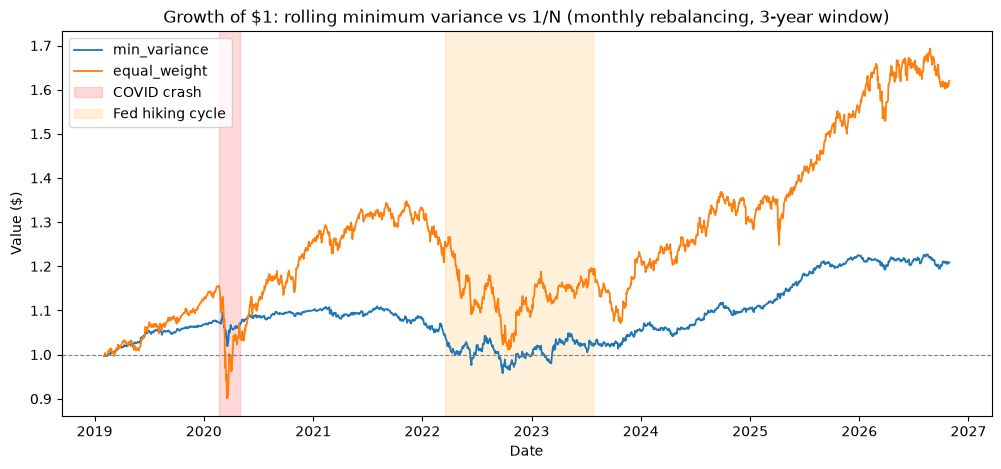

In [10]:
growth = np.exp(backtest.cumsum())

fig, ax = plt.subplots(figsize=(12, 5))
for name in growth.columns:
    ax.plot(growth.index, growth[name], label=name, linewidth=1.3)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")

ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"),
           color="red", alpha=0.15, label="COVID crash")
ax.axvspan(pd.Timestamp("2022-03-16"), pd.Timestamp("2023-07-26"),
           color="orange", alpha=0.15, label="Fed hiking cycle")

ax.set_title("Growth of $1: rolling minimum variance vs 1/N (monthly rebalancing, 3-year window)")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend()
plt.show()

**Reading the chart**

- **$1 grows to about $1.21 with minimum variance and $1.62 with 1/N.** The gap opens mainly in the strong equity years (2019, 2020's recovery, 2023–2025).
- **COVID crash:** 1/N falls sharply, while minimum variance barely moves. Over 2020 as a whole, minimum variance had 5.2% volatility vs 19.0% for 1/N.
- **Fed hiking cycle:** this is where **both** strategies had their worst fall. Minimum variance lost 13.7% from August 2021 to September 2022, because rising rates hit its large Treasury position. 1/N lost 24.9% from November 2021 to October 2022, when stocks and bonds fell together. Minimum variance protected well against the growth shock (COVID), but much less against the inflation shock.

## 8. How the weights move over time

The five assets with the largest positions are highlighted; the other five are drawn in gray. The lower panel shows the **total short position** (the sum of the negative weights), which is the amount a broker would have to lend.

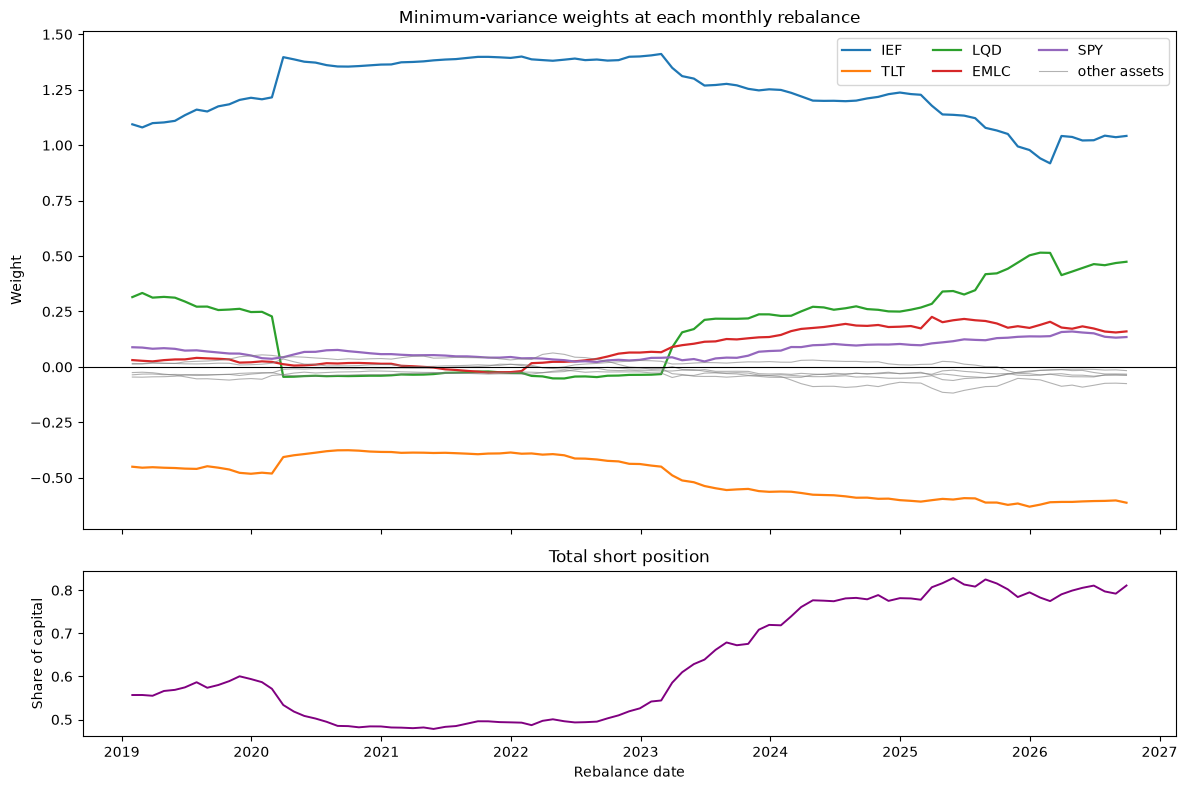

Average weights over the backtest:
SPY     0.075
IWM    -0.011
EFA    -0.013
EEM    -0.002
TLT    -0.494
IEF     1.245
LQD     0.175
EMLC    0.088
GLD    -0.030
VNQ    -0.033
dtype: float64


In [11]:
main_assets = ["IEF", "TLT", "LQD", "EMLC", "SPY"]
other_assets = [t for t in tickers if t not in main_assets]
total_short = -weights_mv[weights_mv < 0].sum(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

for name in main_assets:
    ax1.plot(weights_mv.index, weights_mv[name], label=name, linewidth=1.6)
for j, name in enumerate(other_assets):
    ax1.plot(weights_mv.index, weights_mv[name], color="gray", linewidth=0.8,
             alpha=0.6, label="other assets" if j == 0 else None)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Minimum-variance weights at each monthly rebalance")
ax1.set_ylabel("Weight")
ax1.legend(ncol=3)

ax2.plot(total_short.index, total_short, color="purple", linewidth=1.4)
ax2.set_title("Total short position")
ax2.set_ylabel("Share of capital")
ax2.set_xlabel("Rebalance date")

plt.tight_layout()
plt.show()

print("Average weights over the backtest:")
print(weights_mv.mean().round(3))

**Reading the weights**

- **The portfolio is built around a Treasury pair:** IEF between 94% and 140% (124% on average), financed largely by a TLT short between −38% and −62% (−49% on average). This is the hedge example from Part 2 at work every month: two highly correlated assets with different volatilities.
- **The pair stays stable:** the long IEF / short TLT structure is present in all 93 months, so the strategy's results depend heavily on how intermediate and long Treasuries behave relative to each other.
- **Corporate bonds come and go with the COVID crash:** LQD has a weight of around 25%–33% until early 2020, drops to roughly zero in April 2020 and stays there until March 2023, then rises to about 50% by 2026. LQD had extreme days in March 2020, so while those days are inside the 3-year window the estimator sees it as risky; exactly three years later they leave the window and LQD looks safe again. IEF moves in the opposite direction over the same dates.
- **Equities stay small:** SPY has 4%–14%, and the other risky assets get small short positions.
- **Leverage is high and persistent:** the total short position stays between 48% and 83% of capital (63% on average), so gross exposure is about 2.0–2.7 times capital.

## 9. Turnover and trading costs

At each rebalance, **turnover** measures how much of the portfolio is traded:

$$\text{turnover}_t = \sum_k |a_{k,t} - a_{k,t-1}|$$

If trading costs $c$ per dollar traded (bid-ask spread plus commissions), the cost of that rebalance is $c \times \text{turnover}_t$. For very liquid ETFs like ours, $c$ is roughly 2–10 basis points (0.02%–0.10%).

*Simplification:* we compare each month's target weights with the previous month's target weights, and ignore how the weights drift with prices during the month.

In [12]:
turnover = weights_mv.diff().abs().sum(axis=1).iloc[1:]   # the first rebalance has nothing before it

avg_monthly = turnover.mean()
annual_turnover = avg_monthly * 12
print(f"Average monthly turnover: {avg_monthly:.1%}  (median {turnover.median():.1%})")
print(f"Annual turnover:          {annual_turnover:.1%}")
print()

mv_annual_return = performance(mv_returns)["ann_return"]
for c in [0.0002, 0.0005, 0.0010]:
    cost = annual_turnover * c
    print(f"Cost of {c * 1e4:.0f} bp per dollar traded -> {cost:.3%} per year "
          f"({cost / mv_annual_return:.1%} of the annual return)")

Average monthly turnover: 6.6%  (median 4.4%)
Annual turnover:          79.1%

Cost of 2 bp per dollar traded -> 0.016% per year (0.6% of the annual return)
Cost of 5 bp per dollar traded -> 0.040% per year (1.6% of the annual return)
Cost of 10 bp per dollar traded -> 0.079% per year (3.2% of the annual return)


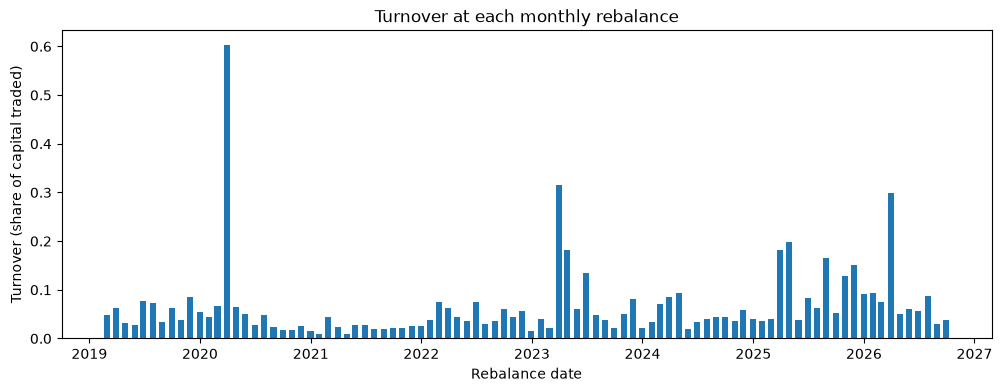

Largest rebalances:
2020-03-31    0.602
2023-03-31    0.315
2026-03-31    0.298
2025-04-30    0.199
2023-04-28    0.181
dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(turnover.index, turnover.values, width=20)
ax.set_title("Turnover at each monthly rebalance")
ax.set_xlabel("Rebalance date")
ax.set_ylabel("Turnover (share of capital traded)")
plt.show()

print("Largest rebalances:")
print(turnover.sort_values(ascending=False).head(5).round(3))

**Reading the turnover**

- **A typical month trades little:** the median turnover is 4.4% of capital, because each month only 1 of the 36 months in the window changes, so $\hat\Sigma$ moves slowly. The annual turnover is about 79%.
- **Costs are negligible:** even at 10 basis points, trading costs are below 0.1% per year. They don't change any conclusion. The borrow fee on the short positions (Part 2) matters more than trading costs.
- **Turnover spikes when extreme days enter or leave the window:** the largest rebalance is March 2020 (60% of capital), when the COVID crash entered the window and changed the covariances abruptly. The second largest is March 2023 (32%), exactly three years later, when those same days dropped out of the window. This is a known side effect of a fixed-length rolling window: one extreme episode moves the weights twice. Other spikes, such as April 2025, coincide with new periods of market stress. An EWMA estimator, which fades old data gradually instead of dropping it all at once, would smooth these jumps.

## 10. Extension: no-trade band

**Rule:** at each month-end, compute the new target weights, but **only trade if**

$$\sum_k |a_{k,\text{new}} - a_{k,\text{current}}| > \text{threshold}$$

Otherwise, keep the current weights for another month. The idea is to avoid trading on small changes that are mostly estimation noise, and to save trading costs.

The loop is the same as in section 5, with one difference: it keeps a variable with the **current** weights and only replaces it when the change is large enough. With a threshold of 0, it trades every month and reproduces section 5 exactly.

In [14]:
def backtest_with_threshold(threshold):
    """Rolling min-variance backtest that only rebalances when the change in weights exceeds threshold.

    Returns (daily returns Series, number of trades, total turnover).
    """
    a_current = None
    n_trades = 0
    total_turnover = 0.0
    pieces = []

    for i, t in enumerate(rebalance_dates):
        a_new = min_variance_weights(estimation_window(t).cov().to_numpy())

        if a_current is None:
            # First month: open the initial position
            a_current = a_new
            n_trades += 1
        else:
            change = np.abs(a_new - a_current).sum()
            if change > threshold:
                total_turnover += change
                a_current = a_new
                n_trades += 1

        hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
        hold = returns.loc[(returns.index > t) & (returns.index <= hold_end)]
        pieces.append(hold @ a_current)

    return pd.concat(pieces), n_trades, total_turnover

In [15]:
years = len(mv_returns) / TRADING_DAYS
COST = 0.0005   # 5 basis points per dollar traded

rows = {}
for threshold in [0.0, 0.05, 0.10, 0.20]:
    r_th, n_trades, total_turnover = backtest_with_threshold(threshold)
    rows[f"{threshold:.0%}"] = pd.concat([
        pd.Series({
            "n_trades": n_trades,
            "annual_turnover": total_turnover / years,
            "annual_cost_5bp": total_turnover / years * COST,
        }),
        performance(r_th),
    ])

threshold_table = pd.DataFrame(rows).T
threshold_table.index.name = "threshold"
threshold_table.round(4)

,n_trades,annual_turnover,annual_cost_5bp,ann_return,ann_volatility,return_over_vol,max_drawdown
threshold,,,,,,,
0%,93.0,0.7853,0.0004,0.0246,0.0477,0.5150,-0.1368
5%,54.0,0.6958,0.0003,0.0246,0.0478,0.5146,-0.1365
10%,29.0,0.6007,0.0003,0.0252,0.0479,0.5257,-0.1359
20%,13.0,0.4613,0.0002,0.0249,0.0482,0.5167,-0.1379


**Reading the no-trade band**

- **It cuts trading a lot:** with a 10% threshold the portfolio trades 29 times instead of 93, and with 20% only 13 times. Annual turnover falls from about 78% to 46%.
- **Risk barely changes:** volatility stays at about 4.8% and the maximum drawdown at about −13.6% to −13.8% for every threshold. Skipping small rebalances does not let the risk drift in a meaningful way.
- **But the savings are tiny:** at 5 basis points, the trading cost falls from about 0.04% to 0.02% per year. The differences in return between thresholds (2.46%–2.52%) are of the same order and mostly noise.
- **Conclusion:** the band works as intended (fewer trades, same risk), but with liquid ETFs the cost it saves is too small to matter. It would matter more with less liquid assets, higher trading costs, taxes on realized gains, or a shorter estimation window, which makes the weights move more.

## 11. Leveraged minimum variance

Minimum variance takes much less risk than 1/N, so comparing their returns directly is not entirely fair. A classic argument says: if minimum variance had a better risk/return trade-off, you could **borrow money to leverage it** up to the same volatility as 1/N, and then it would earn more. This section tests that idea.

**Leverage without look-ahead.** Using the final realized volatilities (4.77% vs 11.64%) to choose the leverage would use information from the future. Instead, at each rebalance date we set

$$L_t = \frac{\hat\sigma_{1/N,t}}{\hat\sigma_{MV,t}}$$

where both volatilities are estimated on the same 3-year window used for the weights. During the following month we hold $L_t$ times the minimum-variance portfolio.

**Financing cost.** Leverage means borrowing $L_t - 1$ for every dollar of capital, and the borrowed money pays interest. We use the T-bill rate from section 6 as the borrowing rate. This is optimistic: real investors borrow at a higher rate, so the true result would be somewhat worse.

**What to expect.** Borrowing or lending at the risk-free rate scales both the excess return and the volatility by the same factor, so **leverage does not change the Sharpe ratio**. Leverage only helps if the strategy has a positive Sharpe ratio, higher than the benchmark's. Section 7 showed that minimum variance's Sharpe ratio was slightly negative, so leverage should not help here; this section measures by how much it hurts, and what it does to the drawdown.

*Technical note:* leverage and interest are applied to **simple** returns ($e^{r} - 1$), not log returns, because a leveraged position's daily gain is $L$ times the simple return minus the interest on the loan.

In [16]:
# Leverage at each rebalance: estimated 1/N volatility / estimated min-variance volatility (same window)
leverage = {}
for t in rebalance_dates:
    Sigma_t = estimation_window(t).cov().to_numpy()
    a_t = weights_mv.loc[t].to_numpy()
    leverage[t] = np.sqrt(a_ew @ Sigma_t @ a_ew) / np.sqrt(a_t @ Sigma_t @ a_t)
leverage = pd.Series(leverage)

# Each day uses the leverage chosen at the previous rebalance (same holding periods as section 5)
lev_pieces = []
for i, t in enumerate(rebalance_dates):
    hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
    days = backtest.index[(backtest.index > t) & (backtest.index <= hold_end)]
    lev_pieces.append(pd.Series(leverage[t], index=days))
lev_daily = pd.concat(lev_pieces)

print(f"Leverage: average {leverage.mean():.2f}x, from {leverage.min():.2f}x to {leverage.max():.2f}x")

Leverage: average 3.02x, from 1.94x to 4.70x


In [17]:
simple = np.exp(backtest) - 1            # log returns -> simple returns

# Leveraged min variance: L times the portfolio, minus interest on the borrowed (L - 1)
simple["mv_levered"] = lev_daily * simple["min_variance"] - (lev_daily - 1) * rf_bt

# Reference only (uses look-ahead): one constant leverage that matches 1/N's realized volatility exactly
L_ex_post = simple["equal_weight"].std() / simple["min_variance"].std()
simple["mv_levered_ex_post"] = L_ex_post * simple["min_variance"] - (L_ex_post - 1) * rf_bt
print(f"Ex-post constant leverage: {L_ex_post:.2f}x")


def performance_rf(simple_returns, rf):
    """Annualized metrics, including the Sharpe ratio, for a Series of daily simple returns."""
    excess = simple_returns - rf
    value = (1 + simple_returns).cumprod()
    drawdown = value / value.cummax() - 1
    return pd.Series({
        "ann_return": np.log1p(simple_returns).mean() * TRADING_DAYS,
        "ann_volatility": simple_returns.std() * np.sqrt(TRADING_DAYS),
        "sharpe_ratio": excess.mean() / excess.std() * np.sqrt(TRADING_DAYS),
        "max_drawdown": drawdown.min(),
        "final_value": value.iloc[-1],
    })


strategies = ["equal_weight", "min_variance", "mv_levered", "mv_levered_ex_post"]
pd.DataFrame({name: performance_rf(simple[name], rf_bt) for name in strategies}).round(4)

Ex-post constant leverage: 2.43x


,equal_weight,min_variance,mv_levered,mv_levered_ex_post
ann_return,0.0625,0.0246,0.0009,0.0164
ann_volatility,0.1161,0.0477,0.1468,0.1160
sharpe_ratio,0.3597,-0.0374,-0.1076,-0.0374
max_drawdown,-0.2494,-0.1368,-0.4519,-0.3156
final_value,1.6203,1.2090,1.0070,1.1353


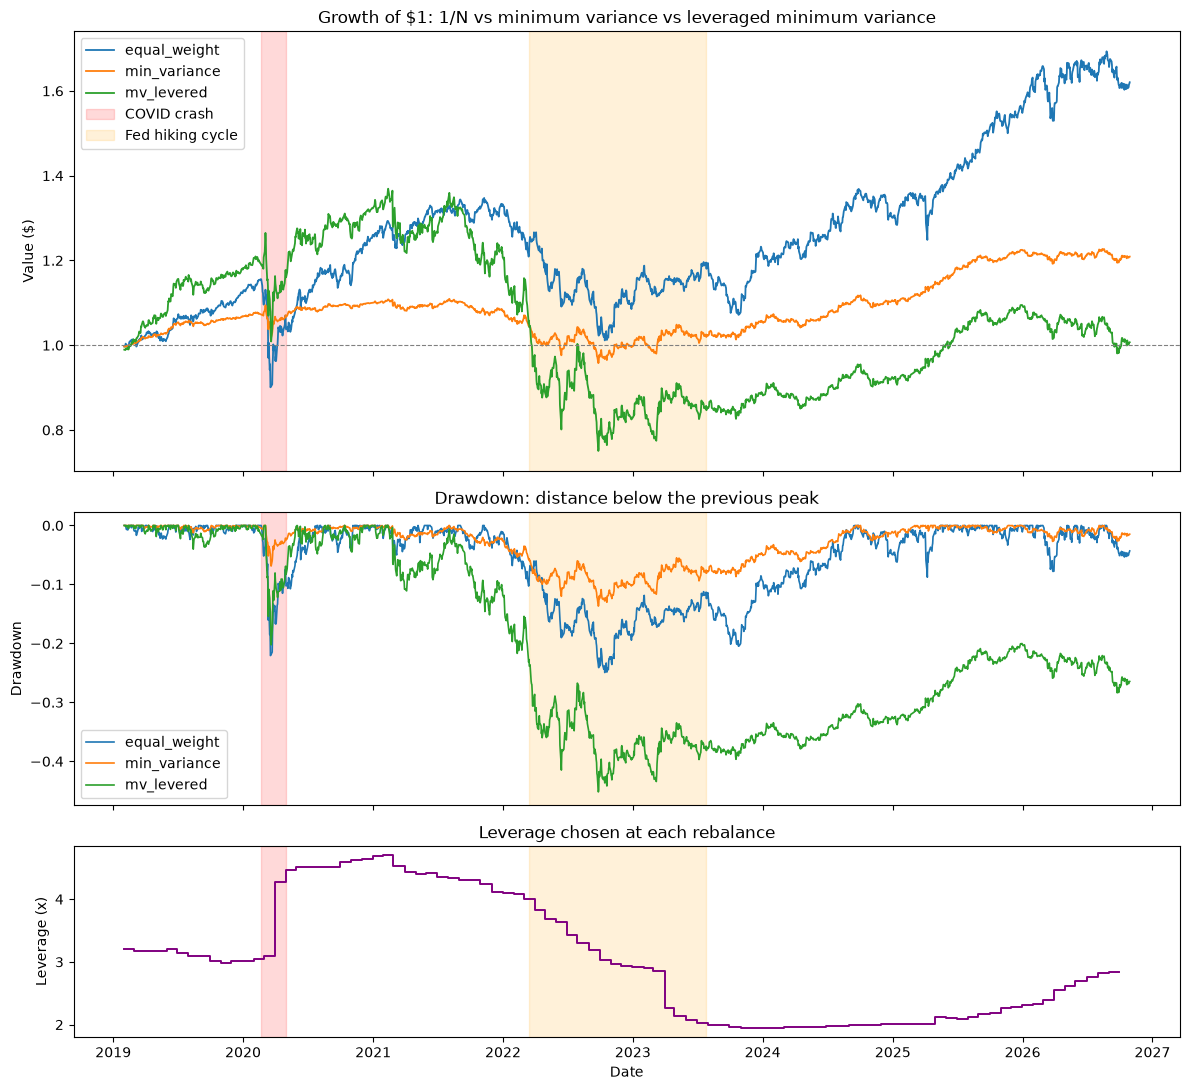

In [18]:
value = (1 + simple[["equal_weight", "min_variance", "mv_levered"]]).cumprod()
drawdown = value / value.cummax() - 1

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 11), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 2, 1.3]})

for name in value.columns:
    ax1.plot(value.index, value[name], label=name, linewidth=1.3)
    ax2.plot(drawdown.index, drawdown[name], label=name, linewidth=1.2)
ax1.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax1.set_title("Growth of $1: 1/N vs minimum variance vs leveraged minimum variance")
ax1.set_ylabel("Value ($)")
ax2.set_title("Drawdown: distance below the previous peak")
ax2.set_ylabel("Drawdown")

ax3.plot(leverage.index, leverage, color="purple", linewidth=1.4, drawstyle="steps-post")
ax3.set_title("Leverage chosen at each rebalance")
ax3.set_ylabel("Leverage (x)")
ax3.set_xlabel("Date")

for ax in (ax1, ax2, ax3):
    ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"), color="red", alpha=0.15,
               label="COVID crash" if ax is ax1 else None)
    ax.axvspan(pd.Timestamp("2022-03-16"), pd.Timestamp("2023-07-26"), color="orange", alpha=0.15,
               label="Fed hiking cycle" if ax is ax1 else None)
ax1.legend()
ax2.legend()

plt.tight_layout()
plt.show()

**Reading the results**

- **Leverage amplified a negative excess return.** Leveraging an asset that earns less than its borrowing cost loses more the more you borrow. The leveraged minimum-variance portfolio ended almost flat ($1.01 vs $1.62 for 1/N), with an annual return close to zero and a Sharpe ratio of −0.11.
- **The drawdown is much worse than 1/N's.** The leveraged portfolio lost about 45% from February 2021 to September 2022, almost twice 1/N's worst fall (−24.9%). With about 3x leverage on a portfolio that is long IEF and short TLT, the 2022 rate shock hit very hard. The low volatility of minimum variance does not survive leverage.
- **The leverage was highest at the worst possible moment.** While the COVID crash was inside the 3-year window (mid-2020 to early 2023), 1/N looked very risky compared with minimum variance, so the leverage rose to about 4.5–4.7x through 2021. The portfolio entered the 2022 rate shock with its largest leverage of the whole backtest, and it was still about 27% below its peak at the end of the sample. Until 2021 the leveraged version was actually ahead of 1/N; the 2022 losses erased that lead.
- **The leverage overshot the target.** Realized volatility was 14.7%, above 1/N's 11.6%. The leverage is set from in-sample volatilities, which underestimate the real out-of-sample risk of minimum variance (the same effect seen in Part 2, where realized volatility was about 2.7 times the in-sample estimate in 2020 and 2022). That pushes the leverage too high, averaging about 3x.
- **Even perfect hindsight doesn't help.** With a constant leverage chosen after the fact to match 1/N's realized volatility exactly (2.43x), the drawdown is −31.6% and the Sharpe ratio stays at −0.04. Leverage can't fix a negative Sharpe ratio.
- **In practice it would be even harder.** On top of the existing short positions, 3x leverage means gross exposure of roughly 6 to 7 times capital, with real borrowing rates above the T-bill rate and the borrow fee on the shorts, both ignored here.

**A caveat about the period.** The general rule holds always: leverage scales risk and excess return together, so it can't turn a negative Sharpe ratio into a positive one. The size of the losses, however, is specific to this sample. 2019–2026 was a bad period for Treasuries (very low yields until 2021, then the 2022 crash), and this leveraged portfolio is mostly a leveraged Treasury position. Over long bond bull markets, such as 1980–2020, leveraged low-risk portfolios performed well, which is the idea behind strategies like risk parity. This backtest shows how that approach can fail when rates rise, not that it always fails.

## 12. Conclusions

1. **Risk.** Over 7.7 years of monthly out-of-sample rebalancing, minimum variance delivered much lower volatility than 1/N (4.8% vs 11.6%) and a much smaller worst fall (−13.7% vs −24.9%). This confirms the single-year results of Part 2 over a long and varied period.

2. **Return and efficiency.** 1/N earned much more (6.3% vs 2.5% per year, so $1 became $1.62 vs $1.21). Minimum variance even earned slightly less than 3-month T-bills (2.75%), so its Sharpe ratio was slightly negative (−0.04) against 0.36 for 1/N. The portfolio behaves like a leveraged Treasury position: it protected very well in the COVID crash (a growth shock) but suffered its worst loss in 2022 (an inflation shock), when Treasuries fell.

3. **Turnover and trading costs.** Re-estimating every month generates moderate turnover (about 79% per year, with spikes when extreme days enter or leave the window, such as March 2020 and March 2023), but with liquid ETFs the trading cost is below 0.1% per year. It doesn't change the conclusions; the borrow fee on the 48%–83% short position is a larger cost.

4. **No-trade band.** Rebalancing only when the weights change by more than 10% or 20% cuts the number of trades by two thirds or more, without changing the risk of the portfolio. In this setting, the cost saved is negligible, so the band is a reasonable simplification rather than a source of performance.

5. **Leverage.** Leveraging minimum variance to 1/N's volatility does not produce a better return: with a negative Sharpe ratio, leverage only amplifies the shortfall. The leveraged version ended almost flat with a −45% drawdown, and even a perfect-hindsight leverage gave −31.6%. Because in-sample volatility underestimates real risk, leverage chosen from the estimation window also overshoots the target volatility. The size of these losses reflects a bad period for Treasuries; the general lesson is that leverage only helps a strategy whose Sharpe ratio is already positive and higher than the alternative.

**Limitations and next steps**

- The strategy relies on large short positions, especially in TLT. A **long-only** version would be more realistic for many investors and is a natural comparison (Part 4).
- The **borrow fee** on the short positions and borrowing rates above the T-bill rate are not included; both would lower the returns of minimum variance further, especially the leveraged version.
- The covariance estimator could be improved with **EWMA** or **Ledoit-Wolf shrinkage**, and different window lengths (1, 2 or 5 years) could be compared, keeping in mind the regime change in the stock–bond correlation found in Part 1.